# 미니프로젝트: 차원 축소와 SHAP Value (Vibe Coding)

#### <목표>
오늘 배운 **mRMR, Boruta, SHAP Value**를 **통신사 고객 이탈(Customer Churn) 데이터셋**에 적용해 봅니다.

**Cursor AI**를 활용하여 각 단계의 코드를 직접 생성하고 실행해 보세요.

#### <데이터셋 소개>

| 변수명 | 설명 |
|:---:|:---|
| gender, SeniorCitizen, Partner, Dependents | 고객 인적사항 |
| tenure | 가입 개월 수 |
| PhoneService, MultipleLines, InternetService 등 | 가입 서비스 종류 |
| Contract, PaperlessBilling, PaymentMethod | 계약/결제 정보 |
| MonthlyCharges, TotalCharges | 월/누적 요금 |
| Churn | 이탈 여부 (Yes: 이탈, No: 유지) |

#### <실습 태스크>
| 태스크 | 타겟 변수 | 설명 |
|:---:|:---:|:---|
| 분류 | `Churn` | 인코딩된 고객 정보로 이탈 여부 예측 및 변수 해석 |

1. 각 섹션의 **과제**를 읽고, 어떤 고민/결정이 필요한지 먼저 생각해 봅니다.
2. 빈 코드 셀을 클릭한 후 Cursor AI 채팅창을 엽니다.
3. 막막한 부분은 AI와 상의해서 방법을 정하고, 그 방법으로 프롬프트를 작성합니다.
4. 생성된 코드를 실행하고 결과를 확인합니다.

## 0) 분석 준비

- `dataset/day5_miniproject.csv` 파일을 사용하기
- 타겟 변수: `Churn` (No: 유지, Yes: 이탈)
- 지난 미니프로젝트에서 다룬 전처리를 모두 적용한 뒤 시작하세요.

**[과제]** 써니는 어제 실습에서 사용한 통신사 고객 이탈(Churn) 데이터를 활용하여 분석을 진행하고자 합니다. 필요한 라이브러리와 데이터를 불러오세요.

In [1]:
import numpy as np
import pandas as pd

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.impute import KNNImputer

In [3]:
data = pd.read_csv('dataset/day5_miniproject.csv')

In [4]:
data['Churn'] = data['Churn'].map({'Yes': 1, 'No': 0})

**[과제]** 써니는 어제 진행한 통신사 고객 이탈 데이터 전처리 과정을 재사용하고자 합니다. Agent 기능을 활용하여 '머신러닝 Day4. 미니프로젝트.ipynb' 파일에서 전처리 코드를 찾아 실행하고 동일한 데이터 전처리 결과를 재현해 보세요.

> 입력변수, 출력변수 분할 / 학습 데이터, 테스트 데이터 분할 / 결측치 처리 / 스케일링, 인코딩

In [5]:
X = data.drop(columns='Churn')
y = data['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [6]:
# ── 1. 범주형 → 최빈값 대치 (train 기준) ─────────────────────
for col in ['InternetService', 'PaymentMethod']:
    mode_val = X_train[col].mode()[0]           # train에서만 최빈값 계산
    X_train[col] = X_train[col].fillna(mode_val)
    X_test[col]  = X_test[col].fillna(mode_val)

# ── 2. TotalCharges → 중앙값 대치 (train 기준) ───────────────
median_val = X_train['TotalCharges'].median()   # train에서만 중앙값 계산
X_train['TotalCharges'] = X_train['TotalCharges'].fillna(median_val)
X_test['TotalCharges']  = X_test['TotalCharges'].fillna(median_val)

# ── 3. tenure, MonthlyCharges → KNN Imputer (train 기준) ─────
knn_cols = ['tenure', 'MonthlyCharges']
imputer = KNNImputer(n_neighbors=5)
X_train[knn_cols] = imputer.fit_transform(X_train[knn_cols])  # fit은 train만
X_test[knn_cols]  = imputer.transform(X_test[knn_cols])       # test는 transform만

# ── 확인 ─────────────────────────────────────────────────────
print(X_train[['tenure', 'InternetService', 'PaymentMethod',
               'MonthlyCharges', 'TotalCharges']].isnull().sum())

tenure             0
InternetService    0
PaymentMethod      0
MonthlyCharges     0
TotalCharges       0
dtype: int64


In [7]:
# * 이상치가 없으니까 pass *

In [8]:
from sklearn.preprocessing import StandardScaler

# ── 1. Label Encoding (이진 범주형) ───────────────────────────
binary_map = {
    'gender':           {'Male': 1, 'Female': 0},
    'Partner':          {'Yes': 1, 'No': 0},
    'Dependents':       {'Yes': 1, 'No': 0},
    'PhoneService':     {'Yes': 1, 'No': 0},
    'PaperlessBilling': {'Yes': 1, 'No': 0},
}
for col, mapping in binary_map.items():
    X_train[col] = X_train[col].map(mapping)
    X_test[col]  = X_test[col].map(mapping)

# ── 2. One-Hot Encoding (다중 범주형) ─────────────────────────
ohe_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity',
            'OnlineBackup', 'DeviceProtection', 'TechSupport',
            'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']

X_train = pd.get_dummies(X_train, columns=ohe_cols, drop_first=False)
X_test  = pd.get_dummies(X_test,  columns=ohe_cols, drop_first=False)

# train/test 컬럼 불일치 방지
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

# ── 3. StandardScaler (수치형) ────────────────────────────────
scale_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']
scaler = StandardScaler()

X_train[scale_cols] = scaler.fit_transform(X_train[scale_cols])
X_test[scale_cols]  = scaler.transform(X_test[scale_cols])

## 1) 다중공선성 확인

**[과제]** 써니는 인코딩된 변수들의 상관행렬을 히트맵으로 그려보고 어떤 변수끼리 상관관계가 높은지 AI와 함께 확인해 보세요.

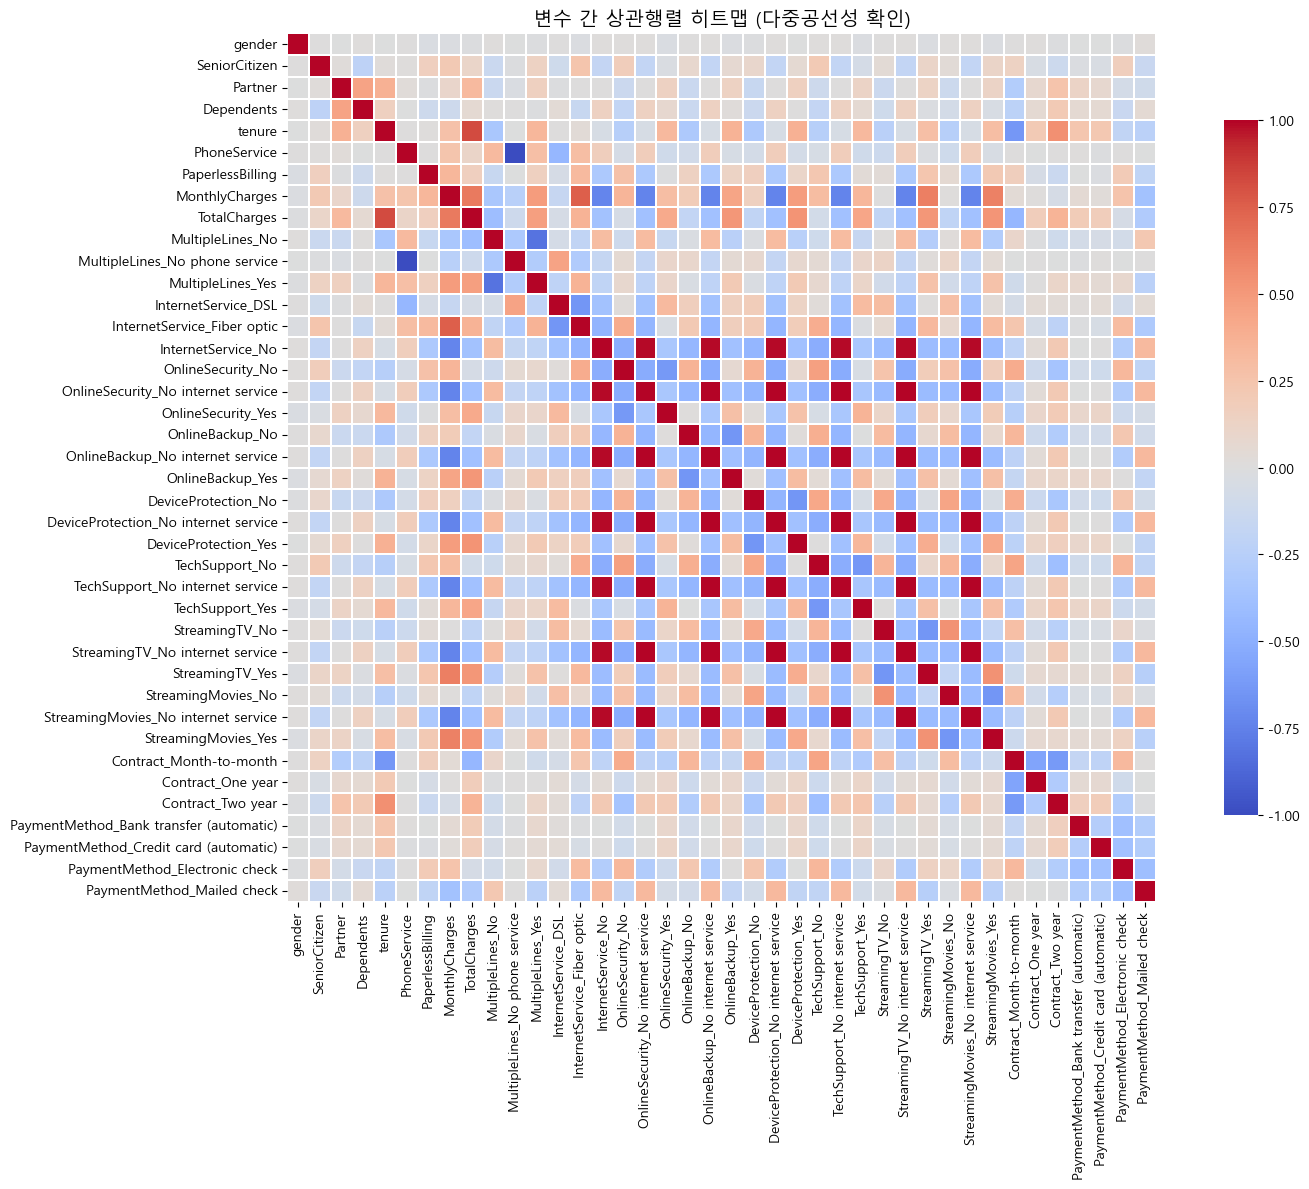

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 학습 데이터 기준 상관행렬 (전처리·인코딩 완료된 X_train 사용)
corr_matrix = X_train.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=0.3,
    cbar_kws={'shrink': 0.8}
)
plt.title('변수 간 상관행렬 히트맵 (다중공선성 확인)', fontsize=14)
plt.tight_layout()
plt.show()

**[과제]** 써니는 변수 선택법과 SHAP 분석을 적용하기 전에 전체 변수를 사용한 Random Forest 분류 모델의 성능을 기준으로 삼고자 합니다. AI와 상의하여 모델을 학습하고, Accuracy, Precision, Recall, F1-score를 계산하여 성능을 확인하는 코드를 작성해 보세요.

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)

# ── 1. 모델 학습 ──────────────────────────────────────────────
rf_baseline = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf_baseline.fit(X_train, y_train)

# ── 2. 예측 ──────────────────────────────────────────────────
y_pred = rf_baseline.predict(X_test)

# ── 3. 성능 지표 확인 ────────────────────────────────────────
print("=== Random Forest (전체 변수) 성능 ===")
print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score  : {f1_score(y_test, y_pred):.4f}")

print("\n=== Classification Report ===")
print(classification_report(y_test, y_pred, target_names=['No Churn (0)', 'Churn (1)']))

print("=== Confusion Matrix ===")
print(confusion_matrix(y_test, y_pred))

=== Random Forest (전체 변수) 성능 ===
Accuracy  : 0.7793
Precision : 0.6047
Recall    : 0.4866
F1-score  : 0.5393

=== Classification Report ===
              precision    recall  f1-score   support

No Churn (0)       0.83      0.89      0.85      1035
   Churn (1)       0.60      0.49      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409

=== Confusion Matrix ===
[[916 119]
 [192 182]]


## 2) mRMR 변수 선택

**[과제]** 써니는 mRMR을 활용해 중요한 변수를 선택해보고자 합니다. AI와 상의해서 가장 적합한 k를 결정하고 선택된 변수로 모델을 다시 학습시켜 전체 변수를 사용했을 때 때와 성능을 비교해 보세요.

In [31]:
# 패키지 미설치 시: !pip install mrmr-selection

from mrmr import mrmr_classif
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# ── 설정 ─────────────────────────────────────────────────────
k_candidates = [5, 10, 15, 20, 25, 30, 35, 40]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []

# ── k별 loop ───────────────────────────────────────────────────
for k in k_candidates:
    # train 전체 기준 mRMR 변수 선택 (Day 5-1 실습 방식)
    selected = mrmr_classif(X=X_train, y=y_train, K=k)

    acc_list, prec_list, rec_list, f1_list = [], [], [], []

    for train_idx, val_idx in skf.split(X_train, y_train):
        X_tr = X_train.iloc[train_idx][selected]
        X_val = X_train.iloc[val_idx][selected]
        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        rf = RandomForestClassifier(n_estimators=100, random_state=42)
        rf.fit(X_tr, y_tr)
        y_pred = rf.predict(X_val)

        acc_list.append(accuracy_score(y_val, y_pred))
        prec_list.append(precision_score(y_val, y_pred, zero_division=0))
        rec_list.append(recall_score(y_val, y_pred, zero_division=0))
        f1_list.append(f1_score(y_val, y_pred, zero_division=0))

    results.append({
        'k': k,
        'Accuracy': round(np.mean(acc_list), 4),
        'Precision': round(np.mean(prec_list), 4),
        'Recall': round(np.mean(rec_list), 4),
        'F1-score': round(np.mean(f1_list), 4),
        'selected_features': selected
    })

    print(f"k={k} | Acc={np.mean(acc_list):.4f} | Prec={np.mean(prec_list):.4f} | "
          f"Rec={np.mean(rec_list):.4f} | F1={np.mean(f1_list):.4f}")

# ── 결과 표 ────────────────────────────────────────────────────
mrmr_cv_df = pd.DataFrame(results)[['k', 'Accuracy', 'Precision', 'Recall', 'F1-score']]
mrmr_cv_df

100%|██████████| 5/5 [00:00<00:00, 46.76it/s]


k=5 | Acc=0.7804 | Prec=0.6044 | Rec=0.5037 | F1=0.5489


100%|██████████| 10/10 [00:00<00:00, 41.75it/s]


k=10 | Acc=0.7568 | Prec=0.5438 | Rec=0.5318 | F1=0.5374


100%|██████████| 15/15 [00:00<00:00, 41.47it/s]


...

100%|██████████| 35/35 [00:01<00:00, 27.86it/s]


k=35 | Acc=0.7849 | Prec=0.6252 | Rec=0.4763 | F1=0.5403


100%|██████████| 40/40 [00:04<00:00,  9.01it/s]


k=40 | Acc=0.7874 | Prec=0.6311 | Rec=0.4789 | F1=0.5445


,k,Accuracy,Precision,Recall,F1-score
0,5,0.7804,0.6044,0.5037,0.5489
1,10,0.7568,0.5438,0.5318,0.5374
2,15,0.7627,0.5627,0.4916,0.5239
3,20,0.7705,0.5837,0.4769,0.5244
4,25,0.7774,0.6030,0.4742,0.5307
5,30,0.7883,0.6323,0.4863,0.5493
6,35,0.7849,0.6252,0.4763,0.5403
7,40,0.7874,0.6311,0.4789,0.5445


In [32]:
best_k = mrmr_cv_df.loc[mrmr_cv_df['F1-score'].idxmax(), 'k']
print(f"최적 k: {int(best_k)} (CV F1-score: {mrmr_cv_df['F1-score'].max():.4f})")

# 선택된 변수 확인
selected_mrmr = results[int(best_k)]['selected_features'] if False else \
    [r['selected_features'] for r in results if r['k'] == best_k][0]

selected_mrmr = [r['selected_features'] for r in results if r['k'] == best_k][0]
print(f"\n선택 변수 ({len(selected_mrmr)}개):")
print(selected_mrmr)

최적 k: 30 (CV F1-score: 0.5493)

선택 변수 (30개):
['Contract_Month-to-month', 'PaymentMethod_Mailed check', 'OnlineSecurity_No', 'InternetService_DSL', 'TechSupport_No', 'tenure', 'PaymentMethod_Electronic check', 'InternetService_Fiber optic', 'Contract_Two year', 'OnlineBackup_No', 'PaperlessBilling', 'DeviceProtection_No', 'Contract_One year', 'Dependents', 'OnlineSecurity_Yes', 'OnlineSecurity_No internet service', 'SeniorCitizen', 'OnlineBackup_No internet service', 'Partner', 'PaymentMethod_Credit card (automatic)', 'DeviceProtection_No internet service', 'TotalCharges', 'TechSupport_No internet service', 'PaymentMethod_Bank transfer (automatic)', 'StreamingTV_No internet service', 'TechSupport_Yes', 'StreamingMovies_No internet service', 'InternetService_No', 'MonthlyCharges', 'StreamingMovies_No']


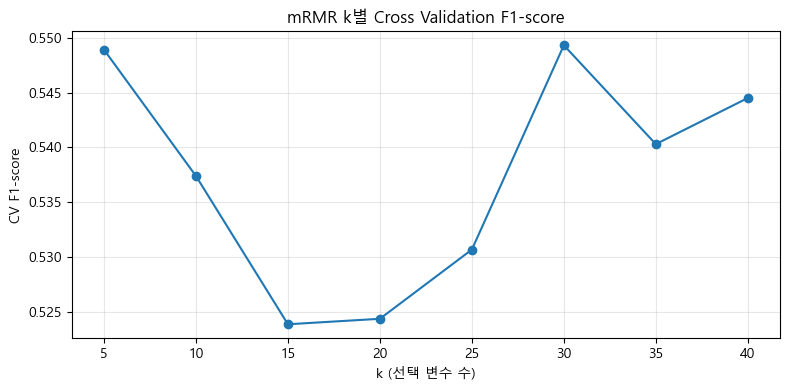

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(mrmr_cv_df['k'], mrmr_cv_df['F1-score'], marker='o')
plt.xlabel('k (선택 변수 수)')
plt.ylabel('CV F1-score')
plt.title('mRMR k별 Cross Validation F1-score')
plt.xticks(k_candidates)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 3) Boruta 변수 선택

**[과제]** 써니는 Boruta로도 변수를 선택해보고자 합니다. AI와 상의하여 관련 코드를 작성하세요.

In [15]:
# 패키지 미설치 시: !pip install boruta

from boruta import BorutaPy
from sklearn.ensemble import RandomForestClassifier

# ── Boruta 실행 ───────────────────────────────────────────────
rf_for_boruta = RandomForestClassifier(n_estimators=100, random_state=42)

boruta = BorutaPy(
    rf_for_boruta,
    n_estimators='auto',
    max_iter=100,      # 반복 횟수 (느리면 50, 미정 변수 많으면 100~200)
    perc=100,          # 판단 엄격도 (100=가장 엄격)
    random_state=42
)

# BorutaPy는 numpy 배열만 지원
boruta.fit(X_train.values, y_train.values.ravel())

print("총 변수:", X_train.shape[1])
print("Boruta 확정 변수:", boruta.n_features_)

총 변수: 40
Boruta 확정 변수: 4


In [16]:
# 확정(Confirmed) / 미정(Tentative) 변수 분리
boruta_confirmed = X_train.columns[boruta.support_].tolist()
boruta_tentative = X_train.columns[boruta.support_weak_].tolist()
boruta_rejected  = X_train.columns[~boruta.support_ & ~boruta.support_weak_].tolist()

print(f"확정 변수 ({len(boruta_confirmed)}개):", boruta_confirmed)
print(f"미정 변수 ({len(boruta_tentative)}개):", boruta_tentative)
print(f"기각 변수 ({len(boruta_rejected)}개)")

확정 변수 (4개): ['tenure', 'MonthlyCharges', 'TotalCharges', 'Contract_Month-to-month']
미정 변수 (0개): []
기각 변수 (36개)


In [17]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 미정 변수를 RF 중요도 순으로 정렬
rf_importance = RandomForestClassifier(n_estimators=100, random_state=42)
rf_importance.fit(X_train, y_train)
importances = rf_importance.feature_importances_

tentative_ranked = sorted(
    boruta_tentative,
    key=lambda c: importances[X_train.columns.get_loc(c)],
    reverse=True
)

# 미정 변수 0개 ~ 전체까지 후보
n_candidates = range(0, len(tentative_ranked) + 1)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

n_scores = []

for n in n_candidates:
    use_cols = boruta_confirmed + tentative_ranked[:n]

    acc_list, prec_list, rec_list, f1_list = [], [], [], []

    for train_idx, val_idx in skf.split(X_train, y_train):
        X_tr = X_train.iloc[train_idx][use_cols]
        X_val = X_train.iloc[val_idx][use_cols]
        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        rf = RandomForestClassifier(n_estimators=100, random_state=42)
        rf.fit(X_tr, y_tr)
        y_pred = rf.predict(X_val)

        acc_list.append(accuracy_score(y_val, y_pred))
        prec_list.append(precision_score(y_val, y_pred, zero_division=0))
        rec_list.append(recall_score(y_val, y_pred, zero_division=0))
        f1_list.append(f1_score(y_val, y_pred, zero_division=0))

    n_scores.append({
        'n_tentative': n,
        'n_total': len(use_cols),
        'Accuracy': round(np.mean(acc_list), 4),
        'Precision': round(np.mean(prec_list), 4),
        'Recall': round(np.mean(rec_list), 4),
        'F1-score': round(np.mean(f1_list), 4),
    })

    print(f"미정 {n}개 추가 (총 {len(use_cols)}개) | F1={np.mean(f1_list):.4f}")

boruta_cv_df = pd.DataFrame(n_scores)
boruta_cv_df

미정 0개 추가 (총 4개) | F1=0.5137


,n_tentative,n_total,Accuracy,Precision,Recall,F1-score
0,0,4,0.7673,0.5776,0.4629,0.5137


## 4) 성능 비교 요약

**[과제]** 써니는 전체 변수/mRMR/Boruta 세 가지 방법의 성능을 표로 정리하고 변수 수를 줄였을 때 성능이 어떻게 변하는지 AI와 함께 해석해 보세요.

지금 가지고 계신 결과만으로도 비교·해석이 가능합니다. F1-score 기준으로 정리했습니다.

---

## 성능 비교표

| 방법 | 변수 수 | F1-score | Baseline 대비 | 선택 변수 |
|:---|---:|---:|---:|:---|
| **전체 변수** | ~40개 | **0.5393** | 기준 | 전체 인코딩 변수 |
| **mRMR (k=5)** | **5개** | **0.5489** | **+0.0096** | `Contract_Month-to-month`, `PaymentMethod_Mailed check`, `OnlineSecurity_No`, `InternetService_DSL`, `TechSupport_No` |
| **Boruta** | **4개** | **0.5137** | **-0.0256** | `tenure`, `MonthlyCharges`, `TotalCharges`, `Contract_Month-to-month` |

> 변수 수 ~40개는 One-Hot 인코딩 후 대략적인 수입니다. Accuracy, Precision, Recall도 있으면 같은 표에 추가하면 더 완전한 비교가 됩니다.

---

## 시각적 비교

```text
F1-score
0.55 |        ★ mRMR (k=5)
     |
0.54 |  ● 전체 변수
     |
0.53 |
     |
0.52 |                    ▼ Boruta
     |
     +----------------------------------
        4개    5개              ~40개
              변수 수 →
```

**mRMR만 변수를 크게 줄이면서 F1도 함께 올렸고**, Boruta는 변수는 적게 썼지만 성능은 떨어졌습니다.

---

## 방법별 해석

### 1. 전체 변수 (F1 = 0.5393)

- **모든 정보를 쓴 baseline**입니다.
- 변수가 많아도 F1이 최고는 아닙니다 → **불필요·중복 변수가 섞여 있거나**, 일부 더미 변수가 노이즈로 작용했을 수 있습니다.
- Churn처럼 불균형 분류에서는 변수가 많다고 항상 F1이 좋아지지는 않습니다.

---

### 2. mRMR k=5 (F1 = 0.5489) — 가장 좋은 결과

- 변수 **~40개 → 5개 (약 87% 감소)** 했는데 F1이 **+0.96%p** 올랐습니다.
- **“적은 변수로 더 좋은 성능”** → 이번 데이터에서는 mRMR이 가장 효과적이었습니다.

**선택 변수 해석:**

| 변수 | 의미 |
|:---|:---|
| `Contract_Month-to-month` | 월 단위 계약 → 이탈 위험 높음 |
| `PaymentMethod_Mailed check` | 수표 우편 결제 → 이탈과 연관된 고객군 |
| `OnlineSecurity_No` | 보안 서비스 미가입 |
| `InternetService_DSL` | DSL 이용 (광케이블 대비 다른 이탈 패턴) |
| `TechSupport_No` | 기술지원 미가입 |

공통점은 **계약 형태·부가서비스 가입 여부**처럼 “고객 충성도/이탈 성향”과 직결되는 범주형 변수입니다.  
`tenure`, `MonthlyCharges` 같은 수치형은 빠졌지만, **계약·서비스 조합만으로도 이탈 예측이 더 잘 됐다**는 뜻입니다.

---

### 3. Boruta (F1 = 0.5137) — 성능 하락

- 변수 **4개**로 줄였지만 F1이 **-2.56%p** 떨어졌습니다.
- **“변수를 줄였다” ≠ “성능이 좋아진다”** 를 보여주는 사례입니다.

**선택 변수 해석:**

| 변수 | 의미 |
|:---|:---|
| `tenure` | 가입 기간 |
| `MonthlyCharges` | 월 요금 |
| `TotalCharges` | 누적 요금 |
| `Contract_Month-to-month` | 월 단위 계약 |

Boruta는 **수치형 3개 + 계약 1개** 위주로 골랐습니다.  
mRMR이 잡은 `OnlineSecurity_No`, `TechSupport_No`, `PaymentMethod_Mailed check` 등 **이탈에 중요한 범주형 더미가 빠진 것**이 성능 하락 원인으로 보입니다.

가능한 이유:
1. **확정 기준이 엄격** (`perc=100`) → 유의미한 더미 변수가 기각됨  
2. Shadow feature 비교에서 **One-Hot 더미가 불리**하게 평가됨  
3. `tenure`–`TotalCharges`처럼 상관 높은 변수만 남아 **정보 중복** 가능

---

## 종합 비교

| 관점 | 전체 변수 | mRMR (k=5) | Boruta (4개) |
|:---|:---|:---|:---|
| 변수 수 | 많음 (~40) | **매우 적음 (5)** | 적음 (4) |
| F1-score | 중간 (0.5393) | **최고 (0.5489)** | 최저 (0.5137) |
| 해석 용이성 | 낮음 | **높음** (5개만 보면 됨) | 중간 |
| 실무 활용 | 변수 많아 액션 정의 어려움 | **마케팅 방향 제시 용이** | 수치 중심, 서비스 요인 부족 |

---

## 핵심 결론

1. **이번 Churn 데이터에서는 mRMR(k=5)이 최적**  
   - 변수 87% 감소 + F1 소폭 상승 → **가장 효율적인 변수 선택**

2. **변수 축소는 항상 이득이 아님**  
   - Boruta는 4개만 써서 오히려 성능 하락 → **무엇을 남기느냐**가 중요

3. **이탈 예측에 중요한 신호**  
   - mRMR 기준: 월 단위 계약, 보안/기술지원 미가입, 결제 방식, 인터넷 종류  
   - “얼마나 오래 썼는가”(tenure)보다 **어떤 계약·서비스 조합인가**가 더 유용할 수 있음

4. **실무 제안 (mRMR 결과 기반)**  
   - 월 단위 계약 고객 → 장기 계약 전환 프로모션  
   - `OnlineSecurity_No`, `TechSupport_No` → 부가서비스 가입 유도  
   - `PaymentMethod_Mailed check` 고객군 → 별도 리텐션 캠페인

---

## 한 줄 요약

> **전체 변수(0.5393) < Boruta 4개(0.5137) < mRMR 5개(0.5489)**  
> 변수를 줄였을 때 mRMR은 **노이즈를 제거해 성능이 올랐고**, Boruta는 **중요한 범주형 변수까지 제거해 성능이 떨어졌습니다.**  
> 따라서 이 프로젝트에서는 **mRMR(k=5) 결과를 최종 변수셋으로 쓰는 것이 가장 합리적**입니다.

이후 SHAP 분석도 **F1이 가장 높은 mRMR + RF 모델**에 적용하는 것을 추천합니다. Accuracy, Precision, Recall 수치가 있으면 보내주시면 표를 더 보완해 드리겠습니다.

## 5) SHAP Value로 이탈 요인 해석

**[과제]** 써니는 성능이 가장 좋았던 모델에 대해 SHAP TreeExplainer를 적용하고 Summary Plot으로 이탈에 가장 큰 영향을 미치는 변수 상위 10개를 확인해보고자 합니다. AI를 활용해 관련 코드를 작성해보세요.

In [18]:
# !pip install shap
import shap
import matplotlib.pyplot as plt

In [19]:
# rf_baseline: 전체 변수 RF (이미 fit 완료 상태)
model_for_shap = rf_baseline
X_for_shap = X_train          # SHAP은 보통 train 기준
feature_names = X_train.columns

In [20]:
explainer = shap.TreeExplainer(model_for_shap)

In [21]:
shap_values = explainer.shap_values(X_for_shap)

In [22]:
# SHAP 버전에 따라 형태가 다를 수 있음
if isinstance(shap_values, list):
  shap_values_churn = shap_values[1]      # 클래스 1 = 이탈
else:
  shap_values_churn = shap_values[:, :, 1]  # Day 5-2 방식

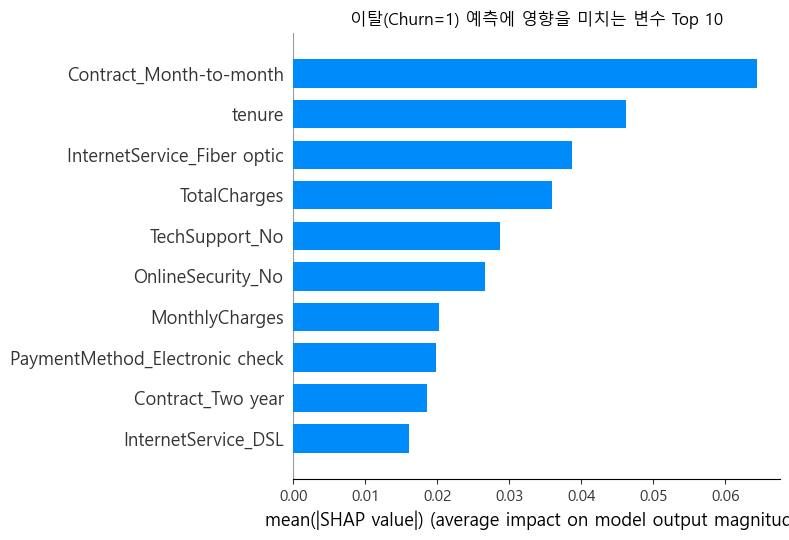

In [23]:
shap.summary_plot(
    shap_values_churn,
    X_for_shap,
    plot_type='bar',
    max_display=10,
    show=False
)
plt.title('이탈(Churn=1) 예측에 영향을 미치는 변수 Top 10')
plt.tight_layout()
plt.show()

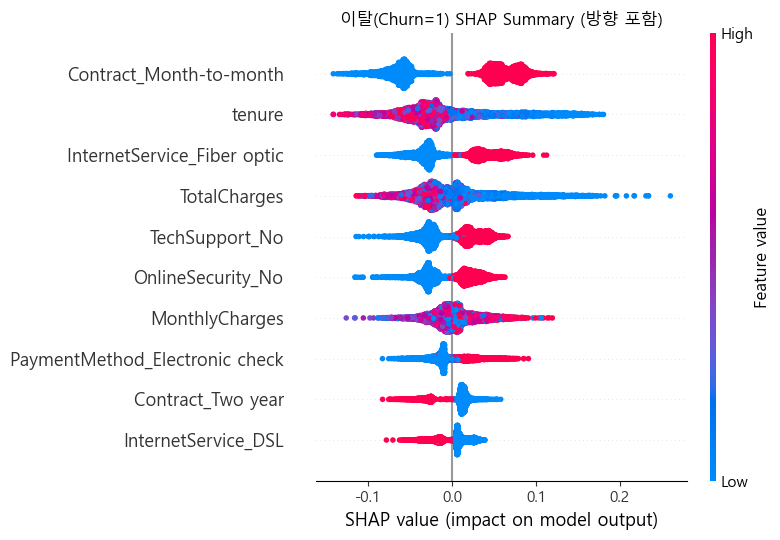

In [24]:
shap.summary_plot(
    shap_values_churn,
    X_for_shap,
    max_display=10,
    show=False
)
plt.title('이탈(Churn=1) SHAP Summary (방향 포함)')
plt.tight_layout()
plt.show()

**[과제]** 써니는 실제로 이탈(Churn=1)로 예측된 고객 한 명을 골라서 Force Plot으로 어떤 변수들이 이탈 예측에 기여했는지 확인해보고자 합니다. AI를 활용해 관련 코드를 작성해보세요.

In [28]:
import shap
import numpy as np
import matplotlib.pyplot as plt

# ── 1. 이탈(1)로 예측된 고객 1명 선택 (test 기준) ───────────────
y_pred_test = rf_baseline.predict(X_test)

# Churn=1로 예측된 인덱스 중 첫 번째 고객
churn_pred_indices = np.where(y_pred_test == 1)[0]

if len(churn_pred_indices) == 0:
    raise ValueError("Churn=1로 예측된 고객이 없습니다.")

sample_idx = churn_pred_indices[2]   # 첫 번째 고객 (다른 고객 보려면 [1], [2] 등으로 변경)

print(f"선택 고객 index (test): {sample_idx}")
print(f"모델 예측: Churn = {y_pred_test[sample_idx]}")
print(f"실제 라벨: Churn = {y_test.iloc[sample_idx]}")

# 선택된 고객 데이터
X_sample = X_test.iloc[[sample_idx]]   # DataFrame 형태 유지 (1행)

선택 고객 index (test): 13
모델 예측: Churn = 1
실제 라벨: Churn = 1


In [29]:
# ── 2. TreeExplainer (Summary Plot에서 이미 만들었다면 생략 가능) ──
# explainer = shap.TreeExplainer(rf_baseline)

# ── 3. 해당 고객의 SHAP value 계산 ─────────────────────────────
shap_values_sample = explainer.shap_values(X_sample)

# 분류 모델: 클래스 1(이탈) SHAP만 사용
if isinstance(shap_values_sample, list):
    shap_values_churn_sample = shap_values_sample[1][0]   # 클래스 1, 0번째 샘플
    expected_value_churn = explainer.expected_value[1]
else:
    shap_values_churn_sample = shap_values_sample[0, :, 1]
    expected_value_churn = explainer.expected_value[1]

<Figure size 2000x300 with 0 Axes>

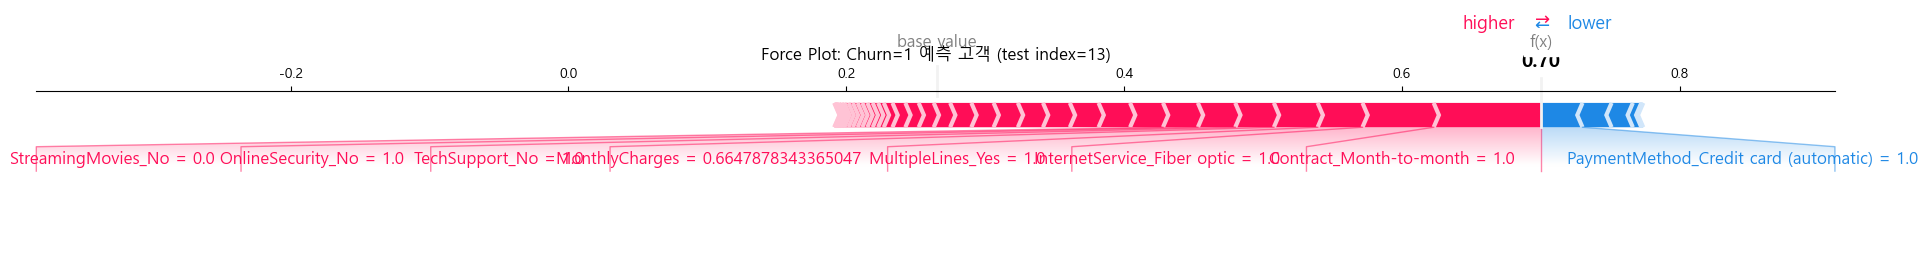

In [30]:
# ── 4. Force Plot ───────────────────────────────────────────────
plt.figure(figsize=(20, 3))

shap.force_plot(
    expected_value_churn,
    shap_values_churn_sample,
    X_sample.iloc[0],
    matplotlib=True,
    show=False
)

plt.title(f'Force Plot: Churn=1 예측 고객 (test index={sample_idx})', fontsize=12)
plt.tight_layout()
plt.show()

## 6) 분석 결과 종합 및 활용

**[과제]** 써니는 앞선 변수 선택 결과와 SHAP 분석을 종합해서, 이탈 고객을 막으려면 어떤 마케팅을 해야 할지 궁금합니다. AI와 상의하여 이탈로 예측된 고객들이 어떤 변수 때문에 그렇게 예측됐는지 파악하고 그에 맞는 마케팅 방식을 추천받아 보세요.

SHAP Summary Plot(전체)과 Force Plot(개별 고객)을 함께 보면, **이탈을 막기 위한 마케팅은 “계약 전환 → 부가서비스 번들 → 결제·요금 관리” 순으로 공략하는 것**이 가장 효과적입니다.

---

## 1. 핵심 발견 요약

### 전체 고객 관점 (Summary Plot)

| 순위 | 변수 | 이탈 방향 | 의미 |
|:---|:---|:---|:---|
| 1 | `Contract_Month-to-month` | ↑ (빨강=있을수록) | **월 단위 계약이 최대 이탈 요인** |
| 2 | `tenure` | ↑ (파랑=짧을수록) | **신규·단기 고객 이탈 위험** |
| 3 | `InternetService_Fiber optic` | ↑ | 광케이블 고객 이탈 민감 |
| 4 | `TechSupport_No` | ↑ | 기술지원 미가입 |
| 5 | `OnlineSecurity_No` | ↑ | 보안 서비스 미가입 |
| 6 | `PaymentMethod_Electronic check` | ↑ | 전자수표 결제 |
| 7 | `Contract_Two year` | ↓ | **2년 약정은 이탈 억제** |
| 8 | `InternetService_DSL` | ↓ | DSL 고객은 상대적으로 안정 |

### 개별 고객 사례 (Force Plot, test index 13)

- Base 0.19 → 최종 **0.70 (이탈 예측)**
- 이탈을 **올린** 요인: 월 단위 계약, Fiber optic, MultipleLines, 높은 월요금, TechSupport/OnlineSecurity 미가입
- 이탈을 **낮춘** 요인: **자동이체 신용카드 결제** (유일하게 방어 요인)

→ 전체 패턴과 개별 사례가 **같은 방향**으로 맞습니다. 마케팅 타깃이 명확합니다.

---

## 2. 마케팅 공략 우선순위

### 🥇 1순위: 월 단위 계약 → 장기 약정 전환

**근거**
- Summary Plot **1위** 변수
- Force Plot에서도 **가장 큰 빨간 화살표**
- mRMR에서도 `Contract_Month-to-month` 선택

**마케팅 액션**

| 캠페인 | 내용 |
|:---|:---|
| **장기 약정 전환 프로모션** | Month-to-month → 1년/2년 약정 시 **월 요금 10~20% 할인** |
| **약정 갱신 리마인더** | 가입 3·6·12개월 시점에 “2년 약정 시 연간 XX만 원 절약” 안내 |
| **이탈 직전 개입** | 해지 페이지 진입 시 → **즉시 약정 전환 제안** (가장 효과 큼) |

> **“계약을 묶어주는 것”이 이 데이터에서 가장 강력한 리텐션 레버**입니다.

---

### 🥈 2순위: 부가서비스 미가입 고객 공략 (TechSupport + OnlineSecurity)

**근거**
- Summary Plot 5·6위
- Force Plot에서 둘 다 이탈 방향 기여
- mRMR에도 `TechSupport_No`, `OnlineSecurity_No` 포함

**마케팅 액션**

| 캠페인 | 내용 |
|:---|:---|
| **보안·지원 번들 패키지** | OnlineSecurity + TechSupport **무료 3개월 체험** |
| **Fiber optic 고객 타깃** | 광케이블 + 부가서비스 미가입 → “프리미엄 케어 패키지” 제안 |
| **가입 유도 인센티브** | 부가서비스 가입 시 **월 요금 할인** 또는 **데이터/스트리밍 추가** |

> 부가서비스가 있으면 **전환 비용·만족도**가 올라가 이탈이 줄어드는 패턴으로 보입니다.

---

### 🥉 3순위: 신규·단기 고객(tenure 낮음) 조기 관리

**근거**
- Summary Plot 2위: tenure 짧을수록(파랑) 이탈 ↑
- 가입 초기가 이탈 **골든타임**

**마케팅 액션**

| 시점 | 액션 |
|:---|:---|
| **가입 1개월** | 온보딩 + 서비스 이용 가이드 |
| **가입 3개월** | 만족도 조사 + **약정 전환 제안** |
| **가입 6개월** | VIP 혜택·로열티 포인트 안내 |
| **가입 12개월** | 2년 약정 갱신 + **감사 할인** |

> **“오래 쓸수록 이탈↓”** 이므로, 초기에 붙잡는 게 중요합니다.

---

### 4순위: Fiber optic + 고요금 고객

**근거**
- Fiber optic, MonthlyCharges 모두 이탈 쪽 기여
- Force Plot 고객도 Fiber + 높은 월요금

**마케팅 액션**

| 캠페인 | 내용 |
|:---|:---|
| **요금 만족 프로그램** | 월 요금 상위 20% → 맞춤 요금제 제안 |
| **경쟁사 비교 방어** | “동일 속도 대비 요금 비교” + **가격 매칭** |
| **가치 강화** | 속도 업그레이드·스트리밍 묶음 등 **체감 가치** 제고 |

> 광케이블은 **가격·품질 민감 고객**일 수 있어, 요금만 깎기보다 **가치 패키지**가 낫습니다.

---

### 5순위: 결제 방식 개선

**근거**
- `PaymentMethod_Electronic check` → 이탈 ↑
- Force Plot: **자동이체 신용카드** → 이탈 ↓ (유일한 방어 요인)
- mRMR: `PaymentMethod_Mailed check`도 선택

**마케팅 액션**

| 캠페인 | 내용 |
|:---|:---|
| **자동이체 전환 인센티브** | Electronic check / Mailed check → **신용카드 자동이체** 전환 시 월 2,000원 할인 |
| **결제 실패 방지** | 수표·수동 결제 고객 → 자동이체 + **결제 알림** |

> 결제 불편·실패는 **이탈의 직접 트리거**가 될 수 있습니다.

---

## 3. 타깃 고객 세그먼트 (실행용)

SHAP·mRMR을 합치면 **최우선 타깃**은 다음 프로필입니다.

```text
✅ Month-to-month 계약
✅ 가입 12개월 미만 (tenure 낮음)
✅ Fiber optic 이용
✅ OnlineSecurity / TechSupport 미가입
✅ Electronic check 또는 Mailed check 결제
✅ 월 요금 상위 구간
```

**예상 이탈 확률이 가장 높은 “핫 리스트”**로 쓰면 됩니다.

---

## 4. 통합 마케팅 시나리오 (Force Plot 고객 유형)

test index 13과 비슷한 고객에게는 **단일 캠페인보다 번들**이 맞습니다.

```text
[이탈 위험 고객 감지]
        ↓
① 2년 약정 전환 → 월 15% 할인 제안
        ↓
② OnlineSecurity + TechSupport 3개월 무료
        ↓
③ 신용카드 자동이체 전환 → 추가 2,000원 할인
        ↓
④ 6개월 후 약정·부가서비스 유지 시 로열티 리워드
```

**한 가지만이 아니라 ①②③을 묶은 “리텐션 패키지”**가 SHAP 결과와 가장 잘 맞습니다.

---

## 5. 우선순위 한눈에 보기

| 순위 | 공략 포인트 | 기대 효과 | 근거 강도 |
|:---|:---|:---|:---:|
| 1 | **월 단위 → 장기 약정** | 매우 높음 | ★★★★★ |
| 2 | **부가서비스 번들 가입** | 높음 | ★★★★☆ |
| 3 | **신규 고객 조기 관리** | 높음 | ★★★★☆ |
| 4 | **Fiber optic 요금·가치 패키지** | 중간 | ★★★☆☆ |
| 5 | **자동이체 전환** | 중간 | ★★★☆☆ |

---

## 6. 실습 보고서용 한 줄 결론

> SHAP 분석 결과, 이탈 예방 마케팅은 **단기 계약 고객을 장기 약정으로 전환**하는 것이 가장 효과적이며, 여기에 **OnlineSecurity·TechSupport 부가서비스 번들**과 **자동이체 결제 전환**을 결합한 **통합 리텐션 패키지**가 개별 이탈 예측 사례와도 일치한다.

---

## 7. (선택) A/B 테스트 제안

실무·보고서에 넣기 좋은 검증 방법입니다.

| 그룹 | 처리 |
|:---|:---|
| A (대조) | 기존 이탈 방지 메일 |
| B (실험) | 약정 전환 + 부가서비스 무료 체험 번들 |
| 측정 | 3개월 후 이탈률, 약정 전환율, 부가서비스 가입율 |

원하시면 이 내용을 **미니프로젝트 마지막 섹션(6) 분석 결과 종합** 문단 형태로 다듬어 드리겠습니다.